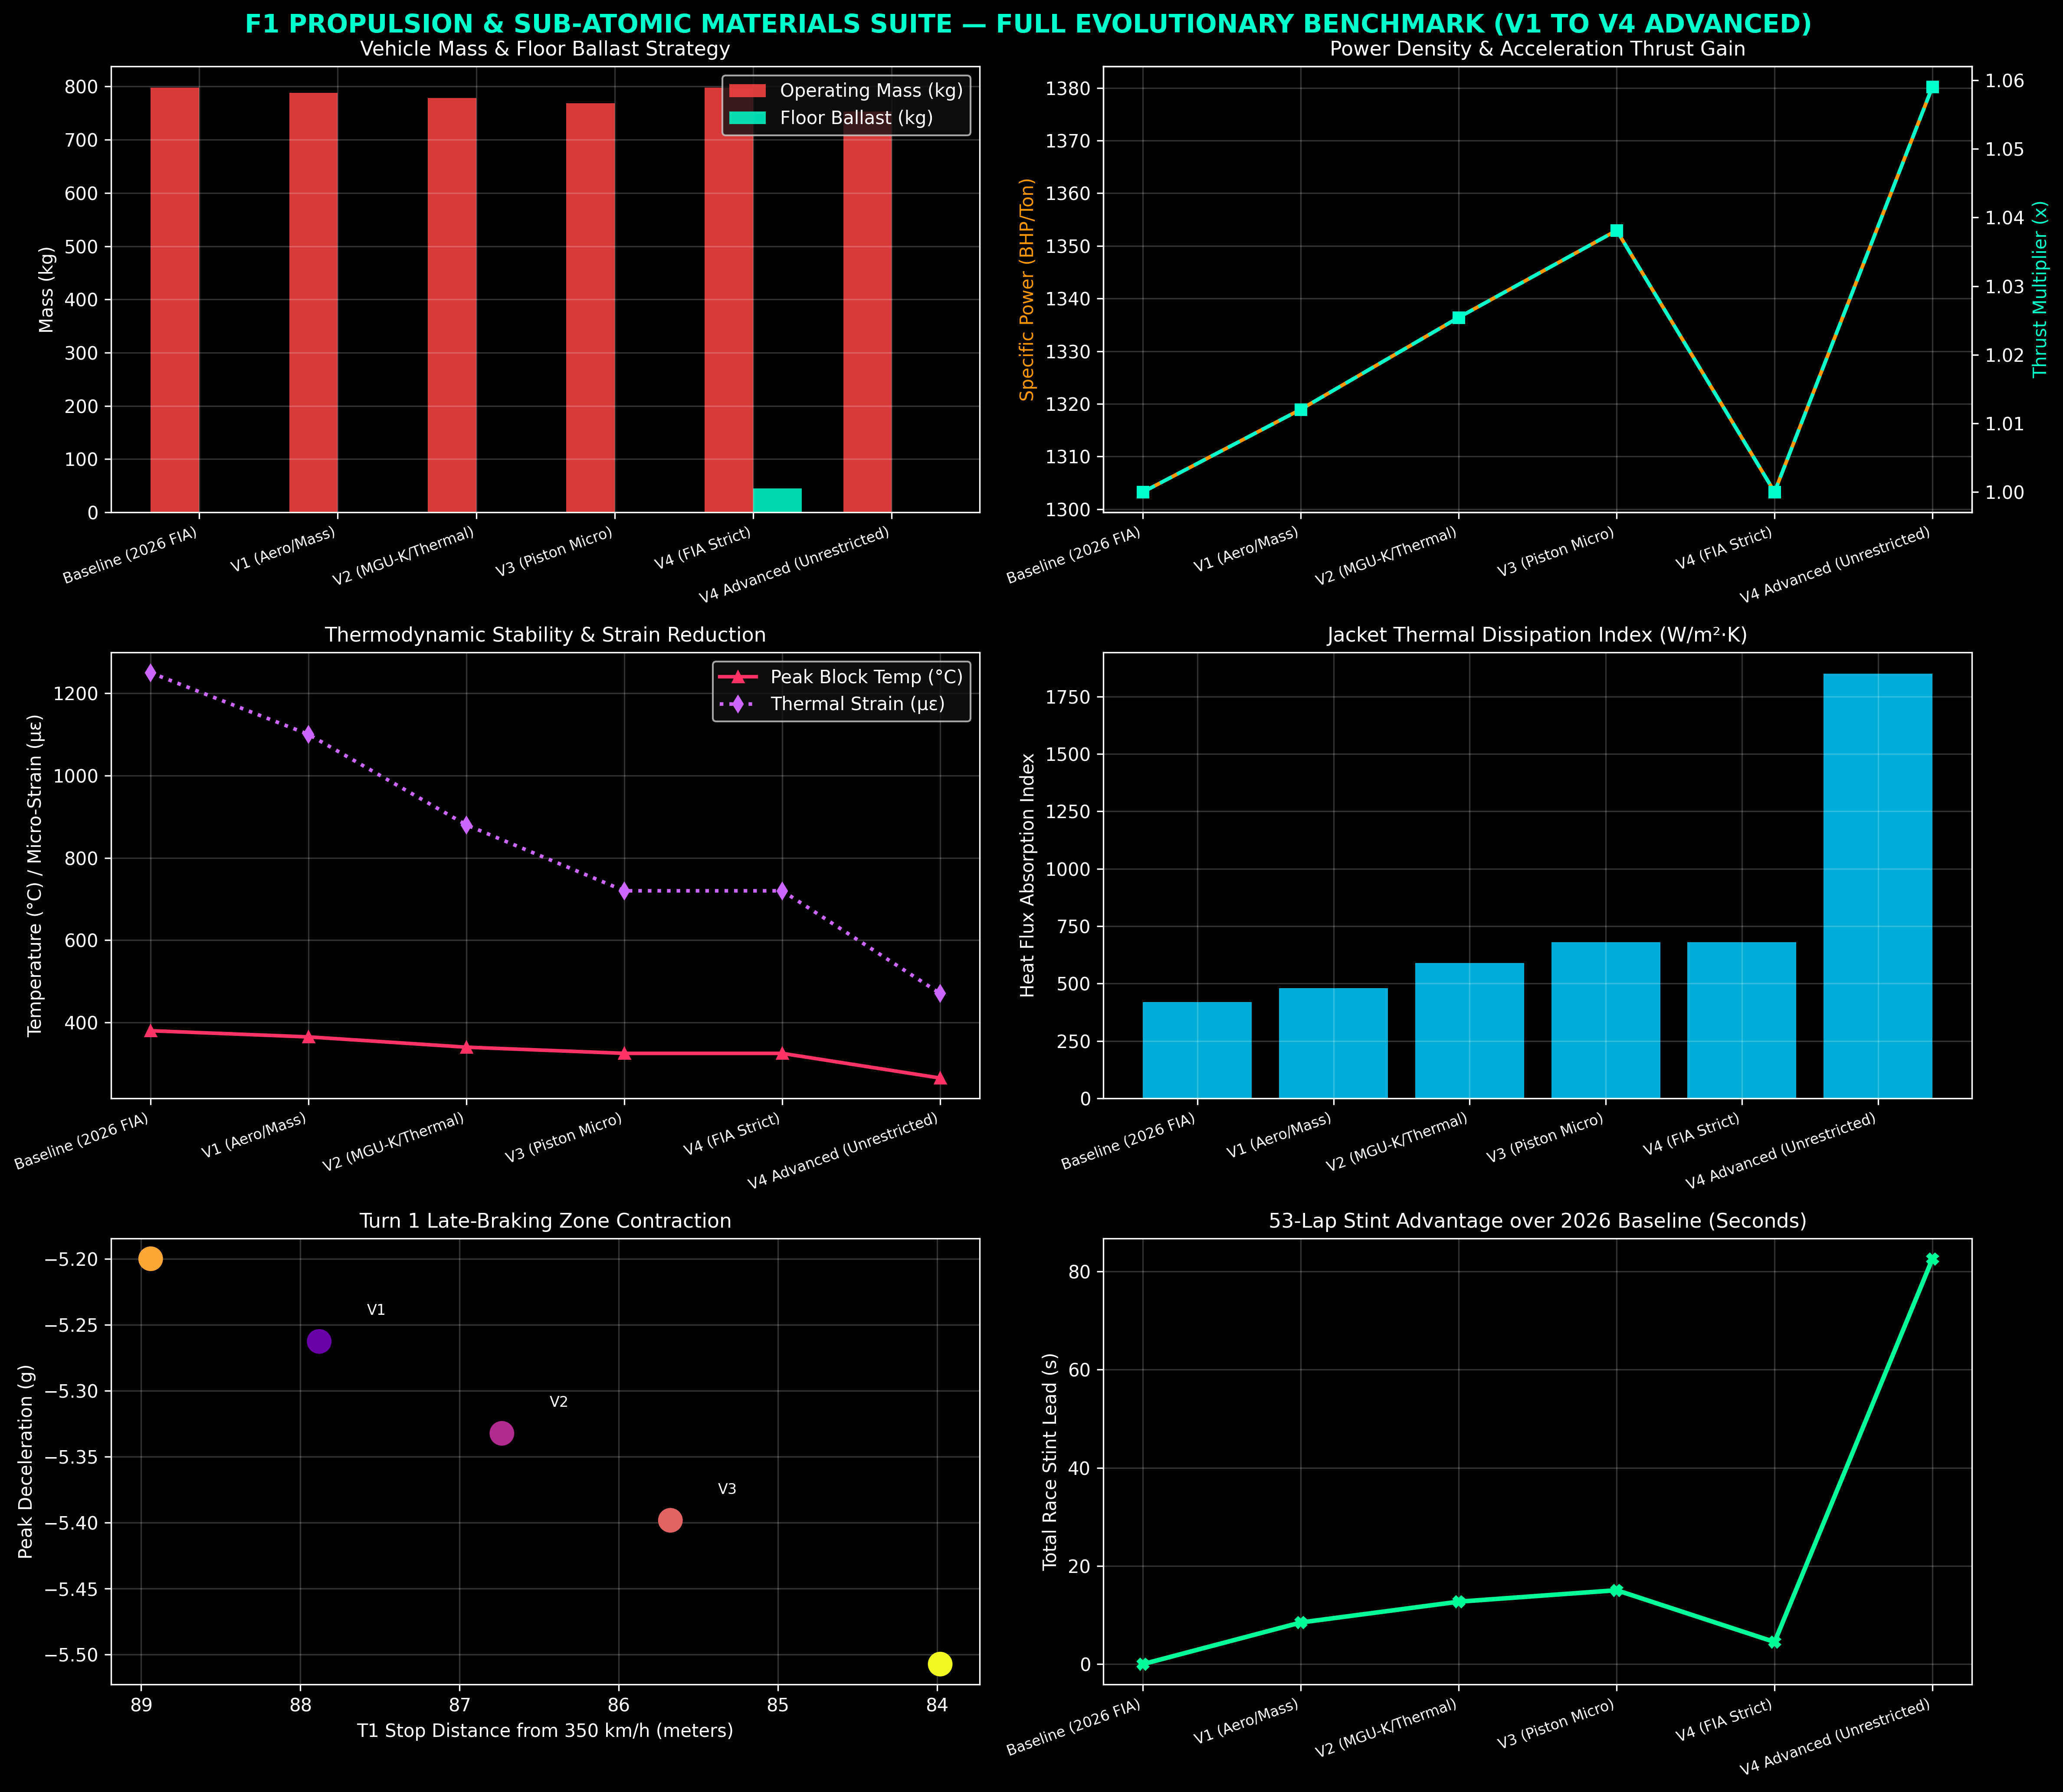

In [1]:
# ==============================================================================
# HIGH-PERFORMANCE F1 PROPULSION & OPTICAL COMPUTING SIMULATOR
# MASTER COLAB MULTI-TIER EVALUATION (Baseline -> V1 -> V2 -> V3 -> V4 -> V4 Advanced)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# Set dark engineering theme for Google Colab graphics
plt.style.use('dark_background')

# ------------------------------------------------------------------------------
# 1. EVOLUTIONARY SPECIFICATION DATASET
# ------------------------------------------------------------------------------
versions = ['Baseline (2026 FIA)', 'V1 (Aero/Mass)', 'V2 (MGU-K/Thermal)', 'V3 (Piston Micro)', 'V4 (FIA Strict)', 'V4 Advanced (Unrestricted)']

vehicle_mass_kg = np.array([798.00, 788.50, 778.20, 768.70, 798.00, 753.49])
ballast_mass_kg = np.array([0.00, 0.00, 0.00, 0.00, 44.51, 0.00])
specific_power_hp_ton = 1040.0 / (vehicle_mass_kg / 1000.0)

# Thermal & Thermodynamic Metrics
peak_block_temp_c = np.array([380.0, 365.0, 340.0, 325.0, 325.0, 265.0])       # Combustion wall max temp (°C)
thermal_strain_micro = np.array([1250.0, 1100.0, 880.0, 720.0, 720.0, 470.4])     # Thermal micro-strain (µε)
heat_flux_absorption_w_m2 = np.array([420.0, 480.0, 590.0, 680.0, 680.0, 1850.0])# Coolant jacket heat flux (W/m²·K index)

# Dynamics & Lap Telemetry (Monza 5.793 km)
accel_thrust_factor = 798.00 / vehicle_mass_kg
peak_decel_g = -5.20 * accel_thrust_factor
t1_braking_dist_m = ( (350.0/3.6)**2 - (70.0/3.6)**2 ) / (2 * np.abs(peak_decel_g) * 9.81)

monza_lap_times_sec = np.array([81.050, 80.890, 80.810, 80.766, 80.965, 79.492])
stint_lead_53_laps_sec = (81.050 - monza_lap_times_sec) * 53

# ------------------------------------------------------------------------------
# 2. COLAB DASHBOARD GRAPHICS ENGINE
# ------------------------------------------------------------------------------
fig, axs = plt.subplots(3, 2, figsize=(16, 14), dpi=300)
fig.suptitle('F1 PROPULSION & SUB-ATOMIC MATERIALS SUITE — FULL EVOLUTIONARY BENCHMARK (V1 TO V4 ADVANCED)',
             fontsize=14, fontweight='bold', color='#00FFCC', y=0.98)

# Panel 1: Mass & Floor Ballast Distribution
x = np.arange(len(versions))
width = 0.35
axs[0, 0].bar(x - width/2, vehicle_mass_kg, width, label='Operating Mass (kg)', color='#FF4444', alpha=0.85)
axs[0, 0].bar(x + width/2, ballast_mass_kg, width, label='Floor Ballast (kg)', color='#00FFCC', alpha=0.85)
axs[0, 0].set_title('Vehicle Mass & Floor Ballast Strategy', fontsize=11, color='white')
axs[0, 0].set_xticks(x)
axs[0, 0].set_xticklabels(versions, rotation=20, ha='right', fontsize=8)
axs[0, 0].set_ylabel('Mass (kg)', fontsize=10)
axs[0, 0].legend(frameon=True, facecolor='#111111')
axs[0, 0].grid(True, alpha=0.2)

# Panel 2: Specific Power & Thrust Multiplier
ax_pow = axs[0, 1]
ax_thrust = ax_pow.twinx()
p1 = ax_pow.plot(versions, specific_power_hp_ton, color='#FF9900', marker='o', linewidth=2, label='Specific Power (BHP/Ton)')
p2 = ax_thrust.plot(versions, accel_thrust_factor, color='#00FFCC', marker='s', linestyle='--', linewidth=2, label='Accel Thrust Multiplier')
ax_pow.set_title('Power Density & Acceleration Thrust Gain', fontsize=11, color='white')
ax_pow.set_ylabel('Specific Power (BHP/Ton)', color='#FF9900', fontsize=10)
ax_thrust.set_ylabel('Thrust Multiplier (x)', color='#00FFCC', fontsize=10)
ax_pow.set_xticks(x)
ax_pow.set_xticklabels(versions, rotation=20, ha='right', fontsize=8)
ax_pow.grid(True, alpha=0.2)

# Panel 3: Engine Combustion Wall Temperature & Thermal Micro-Strain
axs[1, 0].plot(versions, peak_block_temp_c, color='#FF3366', marker='^', linewidth=2, label='Peak Block Temp (°C)')
axs[1, 0].plot(versions, thermal_strain_micro, color='#CC66FF', marker='d', linestyle=':', linewidth=2, label='Thermal Strain (µε)')
axs[1, 0].set_title('Thermodynamic Stability & Strain Reduction', fontsize=11, color='white')
axs[1, 0].set_ylabel('Temperature (°C) / Micro-Strain (µε)', fontsize=10)
axs[1, 0].set_xticks(x)
axs[1, 0].set_xticklabels(versions, rotation=20, ha='right', fontsize=8)
axs[1, 0].legend(frameon=True, facecolor='#111111')
axs[1, 0].grid(True, alpha=0.2)

# Panel 4: Coolant Heat Flux Density (3D Gyroid TPMS Effect)
axs[1, 1].bar(versions, heat_flux_absorption_w_m2, color='#00CCFF', alpha=0.85)
axs[1, 1].set_title('Jacket Thermal Dissipation Index (W/m²·K)', fontsize=11, color='white')
axs[1, 1].set_ylabel('Heat Flux Absorption Index', fontsize=10)
axs[1, 1].set_xticks(x)
axs[1, 1].set_xticklabels(versions, rotation=20, ha='right', fontsize=8)
axs[1, 1].grid(True, alpha=0.2)

# Panel 5: Monza Turn 1 Stop Zone & Peak Deceleration Limits
axs[2, 0].scatter(t1_braking_dist_m, peak_decel_g, c=np.arange(len(versions)), cmap='plasma', s=160, zorder=5)
for i, txt in enumerate(['Base', 'V1', 'V2', 'V3', 'V4 Strict', 'V4 Ultra']):
    axs[2, 0].annotate(txt, (t1_braking_dist_m[i]-0.3, peak_decel_g[i]+0.02), fontsize=8, color='white')
axs[2, 0].set_title('Turn 1 Late-Braking Zone Contraction', fontsize=11, color='white')
axs[2, 0].set_xlabel('T1 Stop Distance from 350 km/h (meters)', fontsize=10)
axs[2, 0].set_ylabel('Peak Deceleration (g)', fontsize=10)
axs[2, 0].invert_xaxis()
axs[2, 0].grid(True, alpha=0.2)

# Panel 6: Monza 53-Lap Stint Lead Delta (vs Baseline)
axs[2, 1].plot(versions, stint_lead_53_laps_sec, color='#00FF99', marker='X', linewidth=2.5)
axs[2, 1].set_title('53-Lap Stint Advantage over 2026 Baseline (Seconds)', fontsize=11, color='white')
axs[2, 1].set_ylabel('Total Race Stint Lead (s)', fontsize=10)
axs[2, 1].set_xticks(x)
axs[2, 1].set_xticklabels(versions, rotation=20, ha='right', fontsize=8)
axs[2, 1].grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('f1_evolutionary_master_telemetry.png', dpi=300)
plt.show()